# Car price regression (205 cars, 24 features)

*Notebook prepared with AI assistance (Claude); I reviewed the results. It mirrors the script in this repo and is for reading the analysis step by step.*

Small data, so the evaluation is careful: repeated cross-validation, a do-nothing baseline, log-price models, and a check that the model is not just memorising car brands.

In [1]:
import pandas as pd, numpy as np, json, sys
from sklearn.model_selection import RepeatedKFold, GroupKFold, cross_val_predict, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Load and tidy
Brand is taken from the car name; a few misspelt makes are fixed.

In [2]:
D = 'data/CarPrice.csv'
c = pd.read_csv(D)
fix = {'maxda':'mazda','porcshce':'porsche','toyouta':'toyota','vokswagen':'volkswagen','vw':'volkswagen'}
c['brand'] = c.CarName.str.split().str[0].str.lower().replace(fix)
c['symboling'] = c.symboling.astype(str)
c.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,brand
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0,alfa-romero
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0,alfa-romero
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0,alfa-romero
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0,audi
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0,audi


In [3]:
y = c.price
X = c.drop(columns=['price','car_ID','CarName'])
cat = X.select_dtypes('object').columns.tolist(); num = [k for k in X.columns if k not in cat]
print(len(c), 'cars;', len(cat), 'categorical,', len(num), 'numeric features')

205 cars; 11 categorical, 13 numeric features


/tmp/ipykernel_666/1503737370.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat = X.select_dtypes('object').columns.tolist(); num = [k for k in X.columns if k not in cat]


## 2. Models

In [4]:
def pre(drop_brand=False):
    cc = [k for k in cat if not (drop_brand and k=='brand')]
    return ColumnTransformer([('c',OneHotEncoder(handle_unknown='ignore'),cc),('n',StandardScaler(),num)])
def log(m): return TransformedTargetRegressor(m, func=np.log, inverse_func=np.exp)
M = lambda db: {
 'baseline: predict mean price': DummyRegressor(),
 'linear regression': make_pipeline(pre(db), LinearRegression()),
 'ridge (log price)': log(make_pipeline(pre(db), RidgeCV(alphas=np.logspace(-2,3,20)))),
 'lasso (log price)': log(make_pipeline(pre(db), LassoCV(cv=5, max_iter=20000, random_state=0))),
 'random forest': make_pipeline(pre(db), RandomForestRegressor(300, random_state=0)),
}


## 3. Repeated 5-fold CV, with and without the brand column

In [5]:
cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=0)
sc = {'r2':'r2','mae':'neg_mean_absolute_error','rmse':'neg_root_mean_squared_error'}
out = {}
for name, db in (('with brand', False), ('without brand', True)):
    out[name] = {}
    for k, m in M(db).items():
        r = cross_validate(m, X, y, cv=cv, scoring=sc, n_jobs=1)
        out[name][k] = {'R2': float(r['test_r2'].mean()), 'R2_sd': float(r['test_r2'].std()), 'MAE': float(-r['test_mae'].mean()), 'RMSE': float(-r['test_rmse'].mean())}
pd.concat({k: pd.DataFrame(v).T.round(3) for k, v in out.items()}, axis=0)

R2  R2_sd       MAE      RMSE
with brand    baseline: predict mean price -0.041  0.080  5932.472  7930.545
              linear regression             0.861  0.102  1836.658  2710.376
              ridge (log price)             0.893  0.053  1563.070  2464.122
              lasso (log price)             0.801  0.112  1958.646  3356.742
              random forest                 0.920  0.033  1469.184  2122.736
without brand baseline: predict mean price -0.041  0.080  5932.472  7930.545
              linear regression             0.858  0.066  1987.797  2806.931
              ridge (log price)             0.852  0.084  1801.840  2879.795
              lasso (log price)             0.789  0.138  2018.855  3426.859
              random forest                 0.919  0.034  1489.742  2145.358

## 4. Does it transfer to makes it has never seen?
Holding out whole brands (GroupKFold) is the harder, more honest test.

In [6]:
# unseen-brand test: does the model transfer to makes it has never seen?
g = GroupKFold(5); gm = {}
for k, m in M(False).items():
    p = cross_val_predict(m, X, y, cv=g, groups=c.brand)
    gm[k] = {'R2': float(1-((y-p)**2).sum()/((y-y.mean())**2).sum()), 'MAE': float(abs(y-p).mean())}
out['unseen brands (GroupKFold by brand)'] = gm
pd.DataFrame(gm).T.round(3)

,R2,MAE
baseline: predict mean price,-0.059,6088.299
linear regression,0.559,3804.208
ridge (log price),0.667,2860.625
lasso (log price),0.721,2625.141
random forest,0.740,2470.396


## 5. What drives price?

{'enginesize': 0.651, 'curbweight': 0.208, 'highwaympg': 0.041, 'horsepower': 0.021, 'carwidth': 0.012, 'wheelbase': 0.009}
{'enginesize': 0.874, 'curbweight': 0.835, 'horsepower': 0.808, 'carwidth': 0.759, 'highwaympg': 0.698}


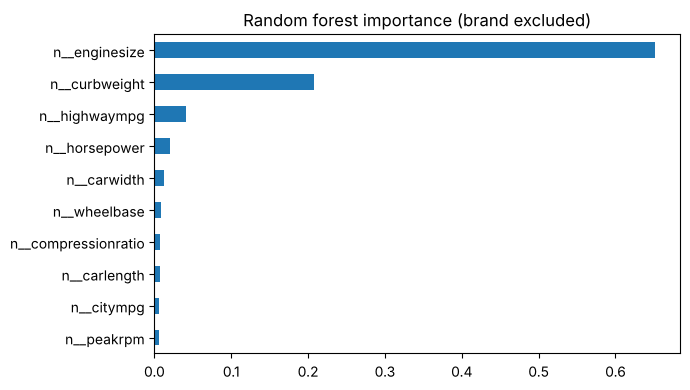

In [7]:
# what drives price (linear model, standardised numerics only)
rf = make_pipeline(pre(True), RandomForestRegressor(300, random_state=0)).fit(X, y)
names = rf[0].get_feature_names_out(); imp = pd.Series(rf[1].feature_importances_, names).sort_values(ascending=False)
out['rf_top_features'] = {k.replace('n__','').replace('c__',''): round(float(v),3) for k, v in imp.head(6).items()}
out['corr_with_price'] = c[num+['price']].corr().price.drop('price').abs().sort_values(ascending=False).head(5).round(3).to_dict()
print(out['rf_top_features']); print(out['corr_with_price'])
imp.head(10)[::-1].plot.barh(figsize=(7,4), title='Random forest importance (brand excluded)'); plt.tight_layout(); plt.show()

## Reading the results
See the README for the written conclusions. Check the gap between the CV score and the unseen-brand score: it shows how much of the fit is brand knowledge. Data is a public teaching dataset of 205 cars, so results describe that sample only.